# 🌐 Multilingual Sentiment Analysis of Customer Reviews (v3, GPU-memory fix)

**8 languages:** English, German, Spanish, French, Japanese, Chinese, Hindi, Hinglish
**Task:** classify a review as **negative / neutral / positive**
**Models:** TF-IDF + Logistic Regression (baseline) vs. fine-tuned XLM-RoBERTa (with and without class weights)

---
## How to use (very simple)

1. **Runtime → Change runtime type → T4 GPU → Save**
2. Edit **only Step 2 (Settings)**, then run cells **top to bottom** with `Shift + Enter`
3. When Step 3 asks, upload **2 files**: `FinalTrainingOnly.tsv` and `ValidationOnly.tsv`
4. Everything else downloads automatically.

## Run it in 3 rounds

| Round | `MODE` | Extra switches in Step 2 | Why |
|---|---|---|---|
| **1. Test** | `"quick"` | set **all True** | Checks that every part runs without errors (a few minutes) |
| **2. Practice** | `"medium"` | `COMPARE_WEIGHTING=True`, others False | Real-looking numbers, faster |
| **3. Final** | `"full"` | **all True**, `SAVE_TO_DRIVE=True` | Numbers for your report |

After changing `MODE`, use **Runtime → Restart session and run all**.

## What is new in v2
- ✅ **Fair comparison:** every language is also scored on negative-vs-positive only (Hindi has no neutral labels, so this makes it comparable)
- ✅ **Class-weighted loss** (helps the weak neutral class), compared against the normal model automatically
- ✅ **Zero-shot experiment:** English-only training vs all-language training
- ✅ **Few-shot Hindi experiment:** how much do 10 or 50 Hindi examples help? (no test-data leakage)
- ✅ Everything is saved into `results.json` for your Lovable app

> **v3 fix:** each trained model is now saved to disk and removed from GPU memory right away, so the second model no longer crashes with "CUDA out of memory". Predictions use a simple loop instead of the Trainer.


## Step 1: Install and check GPU

(A red "dependency resolver" warning after installing is harmless.)

In [ ]:
import os
os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"   # less GPU memory fragmentation
!pip -q install -U datasets "transformers>=4.46" accelerate scikit-learn seaborn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 604.4/604.4 kB 21.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.8/12.8 MB 29.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 29.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 53.9/53.9 MB 13.0 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
cudf-cu13 26.6.0 requires pyarrow<24,>=19.0.0, but you have pyarrow 26.0.0 which is incompatible.


In [ ]:
import torch
print("GPU available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))
else:
    print("⚠️ No GPU! Runtime > Change runtime type > T4 GPU, then run again.")

GPU available: True
GPU name: Tesla T4


## Step 2: Settings (the only cell you edit)

| Setting | Meaning |
|---|---|
| `MODE` | `"quick"` (tiny test), `"medium"`, or `"full"` |
| `COMPARE_WEIGHTING` | `True` = train a normal model AND a class-weighted model, then keep the better one (takes 2× longer) |
| `RUN_ZEROSHOT` | `True` = also train an English-only model (extra training run) |
| `RUN_FEWSHOT` | `True` = few-shot Hindi experiment (short, runs after the main model) |
| `SAVE_TO_DRIVE` | `True` = copy the trained model to your Google Drive at the end |

In [ ]:
import random, numpy as np
from transformers import set_seed

MODE              = "medium"   # "quick" | "medium" | "full"
COMPARE_WEIGHTING = True
RUN_ZEROSHOT      = True
RUN_FEWSHOT       = False
SAVE_TO_DRIVE     = True

PRESETS = {
    "quick":  dict(train=500,  val=100,  test=200,  epochs=1),
    "medium": dict(train=2000, val=300,  test=500,  epochs=2),
    "full":   dict(train=8000, val=1000, test=2000, epochs=3),
}
cfg = PRESETS[MODE]

SEED       = 42
MODEL_NAME = "xlm-roberta-base"
MAX_LEN    = 128
BATCH_SIZE = 16
LR         = 2e-5
HINDI_TEST_N = 400          # Hindi rows kept for testing; the remaining Hindi rows are only used by the few-shot experiment

LABELS     = ["negative", "neutral", "positive"]   # 0, 1, 2
MARC_LANGS = ["en", "de", "es", "fr", "ja", "zh"]

random.seed(SEED); np.random.seed(SEED); set_seed(SEED)
zs_table = None      # filled later if RUN_ZEROSHOT
fs_summary = None    # filled later if RUN_FEWSHOT
print("MODE:", MODE, cfg)

MODE: medium {'train': 2000, 'val': 300, 'test': 500, 'epochs': 2}


## Step 3: Upload your 2 Hinglish files

Click **Choose files** and select `FinalTrainingOnly.tsv` and `ValidationOnly.tsv`.

In [ ]:
import os
from google.colab import files

need = ["FinalTrainingOnly.tsv", "ValidationOnly.tsv"]
if not all(os.path.exists(f) for f in need):
    files.upload()
for f in need:
    print(f, "->", "found ✅" if os.path.exists(f) else "MISSING ❌ (re-run this cell and upload it)")

Saving ValidationOnly.tsv to ValidationOnly.tsv
Saving FinalTrainingOnly.tsv to FinalTrainingOnly.tsv
FinalTrainingOnly.tsv -> found ✅
ValidationOnly.tsv -> found ✅


## Step 4: Load and clean Hinglish (SentiMix)

Cleaning: remove the junk word `nan`, empty rows, duplicates, and training rows that also appear in the test file (leakage).
Labels: 0 = negative, 1 = neutral, 2 = positive (please double-check against the dataset source).

In [ ]:
import re
import pandas as pd

def load_sentimix(path):
    df = pd.read_csv(path, sep="\t", header=None, names=["id", "text", "label"],
                     quoting=3, dtype={"text": str})
    df = df.dropna(subset=["text", "label"])
    df["text"] = df["text"].str.replace(r"(\s+nan)+$", "", regex=True).str.strip()
    df = df[(df.text.str.len() > 0) & (df.text.str.lower() != "nan")]
    df["label"] = df["label"].astype(int)
    df = df[df.label.isin([0, 1, 2])]
    df = df.drop_duplicates("text")
    return df[["text", "label"]].reset_index(drop=True)

hing_train_all = load_sentimix("FinalTrainingOnly.tsv")
hing_test_all  = load_sentimix("ValidationOnly.tsv")      # this file becomes our TEST set
hing_train_all = hing_train_all[~hing_train_all.text.isin(set(hing_test_all.text))].reset_index(drop=True)
hing_train_all = hing_train_all.sample(frac=1, random_state=SEED).reset_index(drop=True)

hing_val = hing_train_all.iloc[:cfg["val"]].copy()
hing_tr  = hing_train_all.iloc[cfg["val"]: cfg["val"] + cfg["train"]].copy()
hing_te  = hing_test_all.sample(n=min(cfg["test"], len(hing_test_all)), random_state=SEED).copy()
for d in (hing_tr, hing_val, hing_te):
    d["language"] = "hinglish"

print("Hinglish rows -> train:", len(hing_tr), "| val:", len(hing_val), "| test:", len(hing_te))

Hinglish rows -> train: 2000 | val: 300 | test: 500


## Step 5: Download Amazon reviews (MARC): en, de, es, fr, ja, zh

Stars → sentiment: **1-2 = negative, 3 = neutral, 4-5 = positive**. Takes a few minutes the first time.

In [ ]:
from datasets import load_dataset

def stars_to_sentiment(stars):
    return np.select([stars <= 1, stars == 2], [0, 1], default=2)   # 0,1->neg | 2->neu | 3,4->pos

marc = {"train": [], "val": [], "test": []}
n_per_split = {"train": cfg["train"], "validation": cfg["val"], "test": cfg["test"]}
key = {"train": "train", "validation": "val", "test": "test"}

for lang in MARC_LANGS:
    print("Loading", lang, "...")
    ds = load_dataset("mteb/AmazonReviewsClassification", lang)
    probe = ds["train"].shuffle(seed=SEED).select(range(2000)).to_pandas()
    base = 1 if (probe.label.min() >= 1 and probe.label.max() == 5) else 0
    assert probe.label.max() - base <= 4, "Unexpected label range, check the dataset card"
    for split in ["train", "validation", "test"]:
        d = ds[split].shuffle(seed=SEED).select(range(min(n_per_split[split], len(ds[split])))).to_pandas()
        d = d[["text", "label"]].copy()
        d["label"] = stars_to_sentiment(d["label"].values - base)
        d["language"] = lang
        marc[key[split]].append(d)
print("Done ✅")

Loading en ...


README.md:   0%|          | 0.00/26.1k [00:00<?, ?B/s]

en/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 26.6MB            

en/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

en/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B /  670kB            

...

zh/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/200000 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/5000 [00:00<?, ? examples/s]

Done ✅


## Step 6: Hindi (IndicSentiment): never used for main training

Hindi rows are split into two **separate** groups so there is no leakage:
- **test** (`HINDI_TEST_N` rows): only for final scoring
- **pool** (the rest): only used by the optional few-shot experiment

In [ ]:
import json
from huggingface_hub import hf_hub_download

hindi_te   = pd.DataFrame(columns=["text", "label", "language"])
hindi_pool = pd.DataFrame(columns=["text", "label", "language"])
try:
    path = hf_hub_download(repo_id="ai4bharat/IndicSentiment", filename="data/test/hi.json", repo_type="dataset")
    try:
        raw = pd.read_json(path, lines=True)
    except ValueError:
        with open(path, encoding="utf-8") as f:
            raw = pd.DataFrame(json.load(f))
    cols = {c.lower().strip(): c for c in raw.columns}
    tmp = pd.DataFrame({"text": raw[cols["indic review"]].astype(str),
                        "label": raw[cols["label"]].astype(str).str.lower().str.strip()})
    print("Raw Hindi label values:", tmp.label.value_counts().to_dict())
    tmp["label"] = tmp["label"].map({"negative": 0, "neutral": 1, "positive": 2})
    tmp = tmp.dropna(subset=["label"]).drop_duplicates("text")
    tmp["label"] = tmp["label"].astype(int)
    tmp["language"] = "hi"
    tmp = tmp.sample(frac=1, random_state=SEED).reset_index(drop=True)
    hindi_te   = tmp.iloc[:HINDI_TEST_N].copy()
    hindi_pool = tmp.iloc[HINDI_TEST_N:].copy()
    print("Hindi test rows:", len(hindi_te), "| Hindi pool (few-shot only):", len(hindi_pool))
except Exception as e:
    print("⚠️ Could not load Hindi:", repr(e), "\nContinuing without Hindi.")
    RUN_FEWSHOT = False

hi.json:   0%|          | 0.00/1.14M [00:00<?, ?B/s]

Raw Hindi label values: {'positive': 506, 'negative': 492, 'none': 2}
Hindi test rows: 400 | Hindi pool (few-shot only): 596


## Step 7: Combine into train / validation / test tables

In [ ]:
train_df = pd.concat(marc["train"] + [hing_tr], ignore_index=True)
val_df   = pd.concat(marc["val"]   + [hing_val], ignore_index=True)
test_df  = pd.concat(marc["test"]  + [hing_te, hindi_te], ignore_index=True)
for d in (train_df, val_df, test_df):
    d["text"] = d["text"].astype(str)

summary = pd.concat({"train": train_df.language.value_counts(),
                     "val": val_df.language.value_counts(),
                     "test": test_df.language.value_counts()}, axis=1).fillna(0).astype(int)
print("Rows per language and split:"); display(summary)
print("Test label counts (0=neg, 1=neu, 2=pos):"); display(pd.crosstab(test_df.language, test_df.label))

Rows per language and split:


,train,val,test
language,,,
en,2000,300,500
de,2000,300,500
es,2000,300,500
fr,2000,300,500
ja,2000,300,500
zh,2000,300,500
hinglish,2000,300,500
hi,0,0,400


Test label counts (0=neg, 1=neu, 2=pos):


label,0,1,2
language,,,
de,198,102,200
en,198,102,200
es,198,102,200
fr,198,102,200
hi,205,0,195
hinglish,139,188,173
ja,198,102,200
zh,198,102,200


## Step 8: Baseline: TF-IDF + Logistic Regression (CPU, ~1-2 min)

In [ ]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import f1_score, classification_report, confusion_matrix

tfidf = TfidfVectorizer(analyzer="char_wb", ngram_range=(1, 4), max_features=300000, sublinear_tf=True)
X_train = tfidf.fit_transform(train_df.text)
clf = LogisticRegression(max_iter=1000, C=2.0, class_weight="balanced").fit(X_train, train_df.label)
tfidf_pred = clf.predict(tfidf.transform(test_df.text))
print("Baseline trained ✅")

Baseline trained ✅


## Step 9: Fine-tune XLM-RoBERTa (the slow step)

If `COMPARE_WEIGHTING = True`, two models are trained:
- **plain** = normal training
- **weighted** = mistakes on rarer classes (like *neutral*) cost more

The one with the better **validation** score is kept (the test set is never used to choose).

In [ ]:
import gc
from datasets import Dataset
from sklearn.utils.class_weight import compute_class_weight
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding)

device = "cuda" if torch.cuda.is_available() else "cpu"
tok = AutoTokenizer.from_pretrained(MODEL_NAME)

def free_gpu():
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()

def to_ds(df):
    ds = Dataset.from_pandas(df[["text", "label"]].reset_index(drop=True))
    return ds.map(lambda b: tok(b["text"], truncation=True, max_length=MAX_LEN),
                  batched=True, remove_columns=["text"])

def compute_metrics(p):
    preds = p.predictions.argmax(-1)
    return {"macro_f1": f1_score(p.label_ids, preds, average="macro"),
            "accuracy": float((preds == p.label_ids).mean())}

class WeightedTrainer(Trainer):
    # same as Trainer, but the loss uses class weights
    def __init__(self, *args, class_weights=None, **kwargs):
        super().__init__(*args, **kwargs)
        self.class_weights = class_weights
    def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):
        labels = inputs["labels"]
        outputs = model(**{k: v for k, v in inputs.items() if k != "labels"})
        w = torch.tensor(self.class_weights, dtype=torch.float, device=outputs.logits.device)
        loss = torch.nn.functional.cross_entropy(outputs.logits.float(), labels, weight=w)
        return (loss, outputs) if return_outputs else loss

def train_model(tr_df, va_df, out_dir, weighted=False):
    # Trains one model, SAVES it to disk, then removes everything from GPU memory.
    # Returns only the folder path + validation score (no big objects kept in memory).
    set_seed(SEED)
    model = AutoModelForSequenceClassification.from_pretrained(
        MODEL_NAME, num_labels=3,
        id2label={i: l for i, l in enumerate(LABELS)},
        label2id={l: i for i, l in enumerate(LABELS)})
    args = TrainingArguments(
        output_dir=out_dir, num_train_epochs=cfg["epochs"],
        per_device_train_batch_size=BATCH_SIZE, per_device_eval_batch_size=64,
        learning_rate=LR, weight_decay=0.01, warmup_steps=50,
        eval_strategy="epoch", save_strategy="epoch",
        load_best_model_at_end=True, metric_for_best_model="macro_f1",
        save_total_limit=1, fp16=torch.cuda.is_available(),
        logging_steps=50, report_to="none", seed=SEED)
    common = dict(model=model, args=args, train_dataset=to_ds(tr_df), eval_dataset=to_ds(va_df),
                  data_collator=DataCollatorWithPadding(tok), compute_metrics=compute_metrics)
    if weighted:
        cw = compute_class_weight("balanced", classes=np.array([0, 1, 2]), y=tr_df.label.values)
        print("Class weights (neg, neu, pos):", cw.round(2))
        trainer = WeightedTrainer(class_weights=cw, **common)
    else:
        trainer = Trainer(**common)
    trainer.train()
    val_f1 = float(trainer.evaluate()["eval_macro_f1"])
    final_dir = f"{out_dir}/final"
    trainer.save_model(final_dir); tok.save_pretrained(final_dir)
    del trainer, model, common
    free_gpu()
    return {"path": final_dir, "val_f1": round(val_f1, 4)}

def load_model(path):
    return AutoModelForSequenceClassification.from_pretrained(path).to(device).eval()

@torch.no_grad()
def predict_probs(model, df, batch_size=64):
    # simple prediction loop: returns an array of shape (rows, 3) with probabilities
    model.eval()
    texts = df["text"].astype(str).tolist()
    out = []
    for i in range(0, len(texts), batch_size):
        enc = tok(texts[i:i + batch_size], truncation=True, max_length=MAX_LEN,
                  padding=True, return_tensors="pt").to(device)
        with torch.autocast("cuda", dtype=torch.float16, enabled=torch.cuda.is_available()):
            logits = model(**enc).logits
        out.append(torch.softmax(logits.float(), dim=-1).cpu().numpy())
    return np.concatenate(out)

trained = {}
print("===== Training: plain =====")
trained["plain"] = train_model(train_df, val_df, "/content/xlmr_plain", weighted=False)
if COMPARE_WEIGHTING:
    print("\n===== Training: class-weighted =====")
    trained["weighted"] = train_model(train_df, val_df, "/content/xlmr_weighted", weighted=True)

val_scores = {k: v["val_f1"] for k, v in trained.items()}
best_name = max(val_scores, key=val_scores.get)
print("\nValidation macro-F1:", val_scores, "-> keeping:", best_name.upper())

config.json:   0%|          | 0.00/615 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

sentencepiece.bpe.model:   0%|          | 0.00/5.07M [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.10M [00:00<?, ?B/s]

===== Training: plain =====


...

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Training Loss,Validation Loss,Epoch,Macro F1,Accuracy
0.580944,0.718547,2,0.688916,0.720476


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]


Validation macro-F1: {'plain': 0.6715, 'weighted': 0.6889} -> keeping: WEIGHTED


## Step 10: Test results per language

Columns explained:
- `*_3class_F1`: macro-F1 over negative/neutral/positive (hard, because of neutral)
- `*_binary_F1`: negative vs positive only (**use this one to compare Hindi with the others**)

In [ ]:
def lang_table(df, preds_dict):
    out = {}
    for name, p in preds_dict.items():
        d = df.assign(pred=p)
        for lang, g in d.groupby("language"):
            present = sorted(g.label.unique())
            row = out.setdefault(lang, {"n_test": len(g)})
            row[f"{name}_3class_F1"] = round(f1_score(g.label, g.pred, average="macro", labels=present, zero_division=0), 4)
            gb = g[g.label != 1]
            row[f"{name}_binary_F1"] = round(f1_score(gb.label, gb.pred, average="macro", labels=[0, 2], zero_division=0), 4)
    t = pd.DataFrame(out).T
    t["n_test"] = t["n_test"].astype(int)
    return t

test_probs = {}
for name, info in trained.items():
    m = load_model(info["path"])
    test_probs[name] = predict_probs(m, test_df)
    del m; free_gpu()

preds = {"TFIDF": tfidf_pred}
for name in trained:
    preds[f"XLMR_{name}"] = test_probs[name].argmax(-1)
final_key  = f"XLMR_{best_name}"
final_pred = preds[final_key]
final_prob = test_probs[best_name]
final_model = load_model(trained[best_name]["path"])     # kept in memory for the later steps

table = lang_table(test_df, preds)
print("Test results per language (higher = better):")
display(table)

# neutral-class check, all languages except Hindi (Hindi has no neutral labels)
non_hi = (test_df.language != "hi").values
neutral_f1 = {name: round(float(f1_score(test_df.label[non_hi], p[non_hi], labels=[1], average=None, zero_division=0)[0]), 4)
              for name, p in preds.items()}
print("\nNeutral-class F1 (pooled, without Hindi):", neutral_f1)

print(f"\nPooled report for {final_key} (all languages):")
print(classification_report(test_df.label, final_pred, target_names=LABELS, zero_division=0))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Test results per language (higher = better):


,n_test,TFIDF_3class_F1,TFIDF_binary_F1,XLMR_plain_3class_F1,XLMR_plain_binary_F1,XLMR_weighted_3class_F1,XLMR_weighted_binary_F1
de,500,0.6512,0.8296,0.7347,0.9008,0.7332,0.8970
en,500,0.6637,0.8319,0.7234,0.8852,0.7378,0.8960
es,500,0.6240,0.8297,0.7178,0.8822,0.7038,0.8929
fr,500,0.6910,0.8543,0.7197,0.9027,0.7532,0.9183
hi,400,0.0144,0.0144,0.7961,0.7961,0.8065,0.8065
hinglish,500,0.5682,0.6679,0.5477,0.7570,0.5904,0.7281
ja,500,0.6175,0.8498,0.7192,0.8864,0.7146,0.8851
zh,500,0.6001,0.8102,0.6621,0.8363,0.6616,0.8583



Neutral-class F1 (pooled, without Hindi): {'TFIDF': 0.4309, 'XLMR_plain': 0.4691, 'XLMR_weighted': 0.4933}

Pooled report for XLMR_weighted (all languages):
              precision    recall  f1-score   support

    negative       0.82      0.73      0.77      1532
     neutral       0.42      0.51      0.46       800
    positive       0.85      0.85      0.85      1568

    accuracy                           0.73      3900
   macro avg       0.70      0.70      0.69      3900
weighted avg       0.75      0.73      0.74      3900



## Step 11: Charts for your report

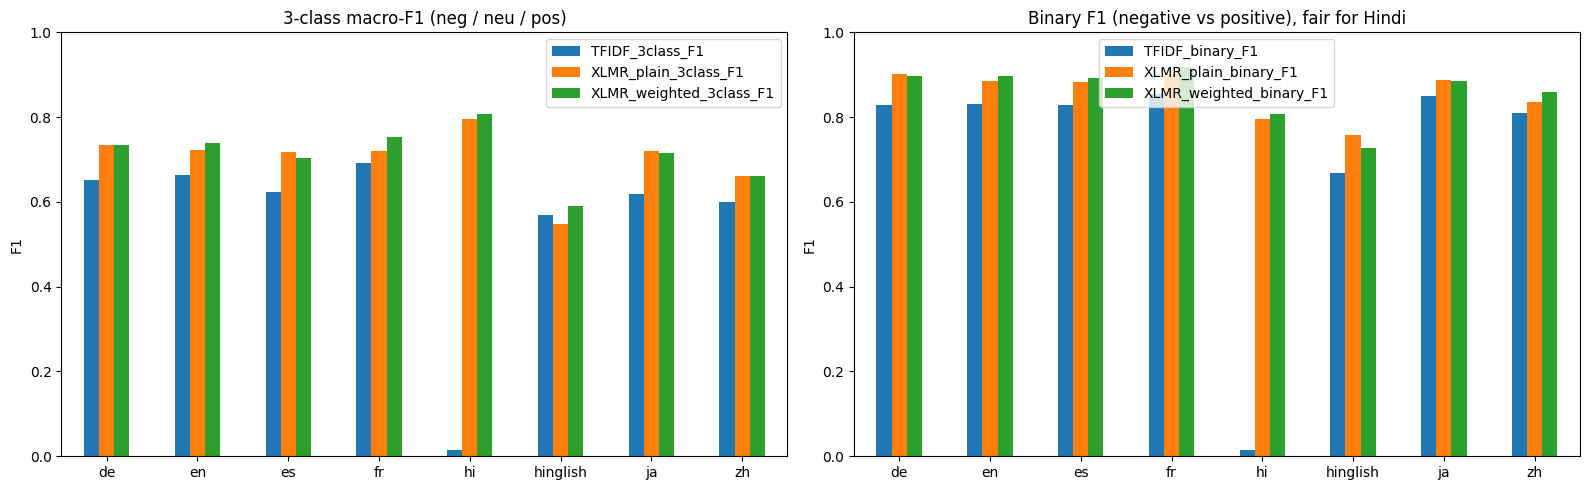

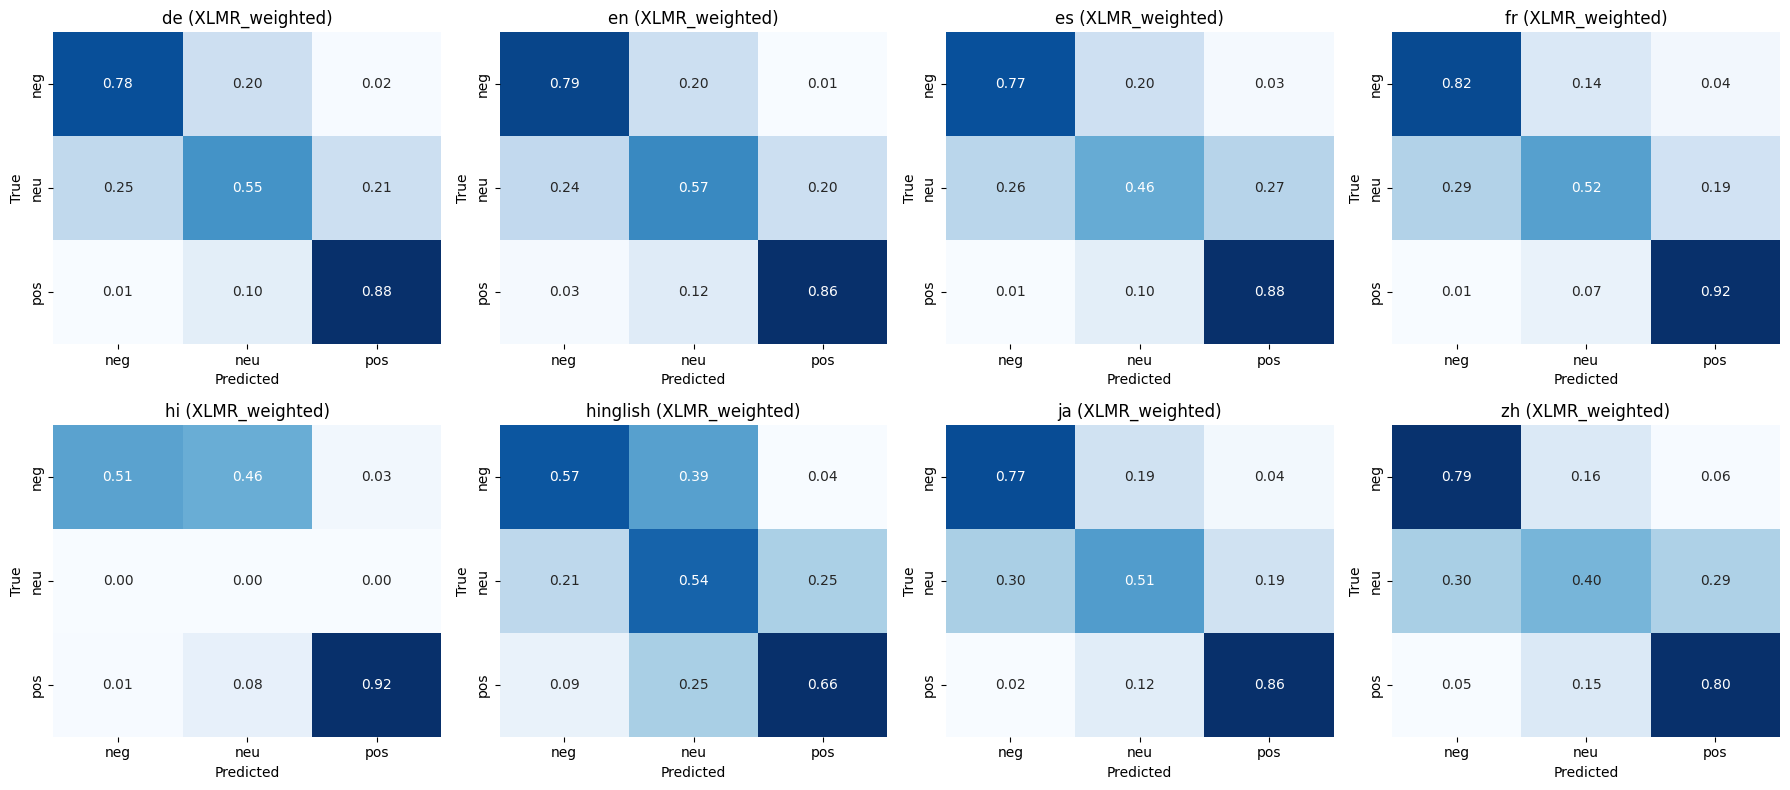

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
for ax, suffix, title in [(axes[0], "3class_F1", "3-class macro-F1 (neg / neu / pos)"),
                          (axes[1], "binary_F1", "Binary F1 (negative vs positive), fair for Hindi")]:
    table[[c for c in table.columns if c.endswith(suffix)]].plot(kind="bar", ax=ax)
    ax.set_title(title); ax.set_ylim(0, 1); ax.set_ylabel("F1"); ax.tick_params(axis="x", rotation=0)
plt.tight_layout(); plt.savefig("f1_by_language.png", dpi=150); plt.show()

langs = sorted(test_df.language.unique())
ncols = 4; nrows = int(np.ceil(len(langs) / ncols))
fig, axes = plt.subplots(nrows, ncols, figsize=(4.5 * ncols, 4 * nrows))
axes = np.array(axes).reshape(-1)
for ax, lang in zip(axes, langs):
    g = test_df.assign(pred=final_pred)[test_df.language == lang]
    cm = confusion_matrix(g.label, g.pred, labels=[0, 1, 2], normalize="true")
    sns.heatmap(np.nan_to_num(cm), annot=True, fmt=".2f", cmap="Blues", cbar=False,
                xticklabels=["neg", "neu", "pos"], yticklabels=["neg", "neu", "pos"], ax=ax)
    ax.set_title(f"{lang} ({final_key})"); ax.set_xlabel("Predicted"); ax.set_ylabel("True")
for ax in axes[len(langs):]:
    ax.axis("off")
plt.tight_layout(); plt.savefig("confusion_matrices.png", dpi=150); plt.show()

## Step 12: Error analysis (read the mistakes!)

For your report, group the mistakes into types: **sarcasm, negation, mixed sentiment, code-mixing, neutral-vs-positive confusion, label noise**.

In [ ]:
errors = test_df.assign(pred=final_pred, confidence=final_prob.max(-1).round(3))
errors = errors[errors.label != errors.pred].copy()
errors["true"] = errors.label.map(dict(enumerate(LABELS)))
errors["predicted"] = errors.pred.map(dict(enumerate(LABELS)))

pd.set_option("display.max_colwidth", 120)
for lang in sorted(errors.language.unique()):
    sub = errors[errors.language == lang]
    print(f"\n===== {lang}: {len(sub)} mistakes (showing 8) =====")
    display(sub[["text", "true", "predicted", "confidence"]].head(8))
errors.to_csv("misclassified_examples.csv", index=False)


===== de: 114 mistakes (showing 8) =====


,text,true,predicted,confidence
502,keine\n\nzu kurz noch probiert aber sonst i.o.,positive,neutral,0.797
503,Toller Duft\n\nHält aber leider nicht lange,positive,neutral,0.570
509,Etwas langweilig\n\nEs plätschert meiner Meinung nach so ohne Pep dahin. Ich habe mir den Film nicht Zu Ende angesehen.,neutral,negative,0.662
515,Hat nicht sehr viel Saugleistung\n\nLieferung und Qualität o.K. aber Saugleistung zu gering.,negative,neutral,0.669
520,Ok\n\nArtikel ist gut verarbeitet und normale teebeutel passen wunderbar rein leider passen die teebeutel die nochma...,neutral,positive,0.524
524,.\n\nFunktioniert eigentlich ganz gut jedoch funktioniert bei mir der Aux anschluss nicht und der lautsprecher zum t...,negative,neutral,0.494
528,Nichts für die Ewigkeit\n\nNach 2 Jahren ist das Sieb gebrochen. Bei dem Preis geht die Nutzungsdauer wohl in Ordnun...,neutral,negative,0.901
531,"Für Golf 2 nicht geeignet..\n\nIch wollte ihn für meinen Golf 2 aber da passt es leider nicht, da das Leder immer wi...",negative,neutral,0.677



===== en: 113 mistakes (showing 8) =====


,text,true,predicted,confidence
0,Not for phone calls\n\nDoes not accommodate phone calls from iPhone. Listening to music while charging works however...,negative,neutral,0.525
1,Cute hat but for narrow faces\n\nI loved the hat but I have a wider face. The bill didn’t quite look right- was too ...,negative,neutral,0.799
2,"I love what this is\n\nI love what this is, but... I placed the stand on a white dresser and it stained it. Then I t...",positive,neutral,0.691
6,"Good idea, poor materials?\n\nThis harness broke the first time we tried to use it. It was easy to put on and seemed...",neutral,negative,0.726
9,"undesirable\n\nquits making ice before basket is half full, and is very noisy",neutral,negative,0.945
10,Easy to install?????\n\nOverall I am quite satisfied with this purchase but it was not that easy for me to install. ...,positive,negative,0.659
11,"A litt\n\nAre fine, just a bit big for a small thin person who is me.",positive,neutral,0.727
12,To double check the product before is sent\n\nThe product suppose to come with the leash Leash is missing,negative,neutral,0.641



===== es: 124 mistakes (showing 8) =====


...

,text,true,predicted,confidence
3001,color tum india wale sari yahi sochti ho ki pakistan wale atankistan h par nhi kuch log lagti h thik pakistani bhuta...,positive,negative,0.477
3002,india 07 kar har maidaan fateh,positive,negative,0.485
3003,mere khayal iss elect congress rjdspbsp ko apn core voter se vote mila nahi,positive,neutral,0.656
3004,om gandhi ko ham isliy rastrapita mant hai kyu ki wo ahinsa vadi ye nahi hote aja,positive,neutral,0.537
3005,ground volunt ko saath lekar chalo unki bhi suno vo ground par hey unh hi pata h,positive,neutral,0.567
3006,msa laugh made fun whole life 'm easili embarrass mean ca n't,positive,neutral,0.563
3007,aditi gud vali ratri aditya jii 😊,neutral,positive,0.503
3008,ballot paper elect karao ek seat bhi nahi milegi bjp ko bjp ko toh koi bus main bhi seat nahi dega,negative,neutral,0.484



===== ja: 122 mistakes (showing 8) =====


,text,true,predicted,confidence
2001,録音ソフトウェアを選ぶのが難点。本体自体も貧弱。\n\n音質は比較的良いが、録音出来るソフトウェアが限られているのが問題。 それと、当方使い方が少々荒いので、ひょんな事で本体に直付けのRCAメスのＲ側が引っこ抜けてしまった。こじ開け...,negative,neutral,0.641
2004,泡立ち\n\n肌に優しいのかなとはおもうけど、泡立ちが悪いので効果の実感はない。,negative,neutral,0.646
2009,レインカバーがついてません\n\nサブ収納部は小分けに収納可能、スマホ入れポーチ、腰ベルトにも左右にポケットがありとても便利です。 A4サイズ本やファイル、タオル、水筒、替えの下着を入れて走って通勤しております。 レインカバーがつい...,neutral,positive,0.700
2010,軽くて、音は小さい。\n\n除草剤を撒くのに、依然の型のものが無くなり、新製品を購入。バッテリーが少し大きくなりましたが持ちは余り変わらない。依然の物は洗い流せたが、新製品は逆さにしないと洗い流せない。耐久性はまだ何とも言えない,positive,neutral,0.549
2018,使うとき必ずスイッチに触れてしまいOFFになる。\n\nどなたかのレビューにもありましたが、持ち手の近くにON、OFFスイッチがあり 巻く時にどんなに頑張ってもOFFに指が当たりOFFにしてしまいます。 それがかなりストレスです。そ...,neutral,negative,0.596
2030,高級感があり良いのだが。。\n\n高級感があり、ベンツに乗っている人にはピッタリです。しかし、今回の品物はサイドに糊の跡があり、それを剥がそうとすると本体の布が一緒に剥がれてしまいます。おそらく初期不良だと思いますが、きちんと現物を...,negative,neutral,0.598
2031,私は、特殊な用途で使っているので参考になりませんが・・・\n\n回すのは楽ですが、強度はあまりありません。先端の交換部品も流用で強度のあるものにしています（あまり交換部品サクっと手に入らないので）。 新品の際はピンにはまるが回される...,negative,neutral,0.759
2032,素材の柔らかさ\n\n柴犬（9kg）に使用。かなり柔らかい+短いので、患部をナメナメしてました（笑）ネタ用としては非常にアリかと思います。,neutral,positive,0.889



===== zh: 144 mistakes (showing 8) =====


,text,true,predicted,confidence
2503,保质期还有三个月\n\n五月初买的，八月份过期；和超市里买来的没有什么区别。,positive,negative,0.714
2509,实用之选\n\n的确够大，式样一般，款式古老，总之就是实用第一。,neutral,positive,0.908
2520,不错\n\n颜色没那么深，枚红色，不过也挺好的，没味道，可以保温很方便分为几个保温档，发现也适中，很人性化的体验，赞一个,neutral,positive,0.964
2523,老客户了\n\n一直买这个油，持续关注中，国内油品食品信任危机，普通百姓还是很难鉴别油品质量，心理因素占很大比例，悲！,positive,neutral,0.537
2525,"比较保暖的内衣\n\n身高180CM,体重72KG，选的M号大了。",neutral,positive,0.854
2526,东拼西凑\n\n文章内容很水，基本是东拼西凑出来的，耽搁时间,negative,neutral,0.615
2531,感觉帮助不大\n\n感觉讲的比较空 没什么太多值得学习的地方,negative,neutral,0.656
2536,还行吧，\n\n是国外一些设计上的理念，在国内语境里可能很难表述出它的绝妙,neutral,positive,0.596


## Step 13 (optional): Zero-shot transfer: English-only vs all languages

Train on **English only** and test on every language. Shows how much the model transfers to languages it never saw.
Runs only if `RUN_ZEROSHOT = True`.

===== Training: English only =====


Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.out_proj.weight  | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

Map:   0%|          | 0/300 [00:00<?, ? examples/s]

...

Training Loss,Validation Loss,Epoch,Macro F1,Accuracy
0.715094,0.713590,2,0.703769,0.740000


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

English-only validation macro-F1: 0.7038


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

,n_test,ALL_LANG_3class_F1,EN_ONLY_3class_F1,ALL_LANG_binary_F1,EN_ONLY_binary_F1,binary_drop_when_EN_only
de,500,0.7332,0.7104,0.8970,0.8824,0.0146
en,500,0.7378,0.7300,0.8960,0.8997,-0.0037
es,500,0.7038,0.6739,0.8929,0.8798,0.0131
fr,500,0.7532,0.7030,0.9183,0.8891,0.0292
hi,400,0.8065,0.7796,0.8065,0.7796,0.0269
hinglish,500,0.5904,0.5168,0.7281,0.7110,0.0171
ja,500,0.7146,0.6814,0.8851,0.8562,0.0289
zh,500,0.6616,0.6262,0.8583,0.8339,0.0244


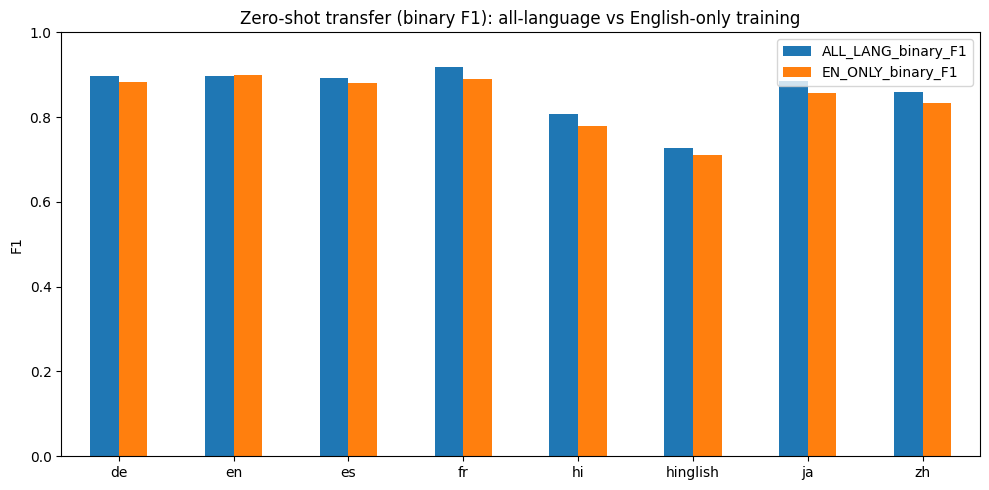

In [ ]:
if RUN_ZEROSHOT:
    print("===== Training: English only =====")
    info_en = train_model(train_df[train_df.language == "en"], val_df[val_df.language == "en"],
                          "/content/xlmr_en_only", weighted=(best_name == "weighted"))
    print("English-only validation macro-F1:", info_en["val_f1"])
    if info_en["val_f1"] < 0.5:
        print("⚠️ This model did not learn properly (too little data/training). Ignore the table below, use MODE='medium' or 'full'.")
    m = load_model(info_en["path"]); en_pred = predict_probs(m, test_df).argmax(-1); del m; free_gpu()
    both = lang_table(test_df, {"ALL_LANG": final_pred, "EN_ONLY": en_pred})
    zs_table = both[["n_test", "ALL_LANG_3class_F1", "EN_ONLY_3class_F1", "ALL_LANG_binary_F1", "EN_ONLY_binary_F1"]].copy()
    zs_table["binary_drop_when_EN_only"] = (zs_table.ALL_LANG_binary_F1 - zs_table.EN_ONLY_binary_F1).round(4)
    display(zs_table)
    zs_table[["ALL_LANG_binary_F1", "EN_ONLY_binary_F1"]].plot(kind="bar", figsize=(10, 5))
    plt.title("Zero-shot transfer (binary F1): all-language vs English-only training")
    plt.ylim(0, 1); plt.ylabel("F1"); plt.xticks(rotation=0); plt.tight_layout()
    plt.savefig("zero_shot_transfer.png", dpi=150); plt.show()
else:
    print("Skipped (RUN_ZEROSHOT = False).")

## Step 14 (optional): Few-shot Hindi: how much do 10 or 50 Hindi examples help?

How it works (short and safe):
- Start from your trained model (it has never seen Hindi in main training).
- Fine-tune it briefly on **k Hindi examples** (taken only from the Hindi *pool*, never from the Hindi *test* rows) plus 200 normal rows so it doesn't forget other languages.
- Score on the Hindi **test** rows. Repeat with 3 random picks per k and report mean ± std.

Runs only if `RUN_FEWSHOT = True`. Hindi is binary, so scores are negative-vs-positive F1.

In [ ]:
import copy

def hindi_binary_f1(pred_labels):
    return f1_score(hindi_te.label, pred_labels, average="macro", labels=[0, 2], zero_division=0)

def few_shot_run(k, seed):
    shots = hindi_pool.sample(n=min(k, len(hindi_pool)), random_state=seed)
    replay = train_df.sample(n=min(200, len(train_df)), random_state=seed)
    parts = [replay] if k == 0 else [pd.concat([shots] * 5), replay]      # shots repeated 5x so they are noticed
    mix = pd.concat(parts).sample(frac=1, random_state=seed)
    model = copy.deepcopy(final_model)
    args = TrainingArguments(output_dir="/content/fewshot_tmp", num_train_epochs=3,
                             per_device_train_batch_size=8, learning_rate=1e-5,
                             save_strategy="no", eval_strategy="no",
                             fp16=torch.cuda.is_available(), report_to="none",
                             logging_steps=1000, seed=seed)
    t = Trainer(model=model, args=args, train_dataset=to_ds(mix[["text", "label"]]),
                data_collator=DataCollatorWithPadding(tok))
    t.train()
    score = hindi_binary_f1(predict_probs(model, hindi_te).argmax(-1))
    del t, model
    free_gpu()
    return score

if RUN_FEWSHOT and len(hindi_pool) >= 50:
    zero_shot_score = hindi_binary_f1(final_pred[(test_df.language == "hi").values])
    rows = [{"setting": "no extra tuning", "k_hindi_examples": 0, "mean_binary_F1": round(zero_shot_score, 4), "std": 0.0, "runs": 1}]
    for k, label in [(0, "control: extra tuning, 0 Hindi"), (10, "10 Hindi examples"), (50, "50 Hindi examples")]:
        scores = [few_shot_run(k, s) for s in [1, 2, 3]]
        rows.append({"setting": label, "k_hindi_examples": k, "mean_binary_F1": round(float(np.mean(scores)), 4),
                     "std": round(float(np.std(scores)), 4), "runs": len(scores)})
        print(f"{label}: scores={np.round(scores, 4)}")
    fs_summary = pd.DataFrame(rows)
    display(fs_summary)
    plt.figure(figsize=(8, 4))
    plt.bar(range(len(fs_summary)), fs_summary.mean_binary_F1, yerr=fs_summary["std"], capsize=4)
    plt.xticks(range(len(fs_summary)), fs_summary.setting, rotation=15, ha="right")
    plt.ylabel("Hindi binary F1"); plt.title("Few-shot Hindi adaptation (with control)")
    plt.ylim(0, 1); plt.tight_layout(); plt.savefig("few_shot_hindi.png", dpi=150); plt.show()
else:
    print("Skipped (RUN_FEWSHOT = False, or no Hindi data).")

Skipped (RUN_FEWSHOT = False, or no Hindi data).


## Step 15: Try your own sentences ✍️

In [ ]:
def predict_text(texts):
    probs = predict_probs(final_model, pd.DataFrame({"text": texts}))
    for t, p in zip(texts, probs):
        print(f"{t}\n   -> {LABELS[p.argmax()].upper()} ({p.max():.0%})  [neg {p[0]:.0%} | neu {p[1]:.0%} | pos {p[2]:.0%}]\n")

predict_text([
    "The product quality is excellent, I love it!",
    "Product bahut accha hai but delivery late thi",
    "यह प्रोडक्ट बहुत अच्छा है",
    "डिलीवरी बहुत खराब थी, पैसे बर्बाद",
    "Das Produkt ist leider schlecht und kaputt angekommen.",
    "とても良い商品です。おすすめします。",
    "质量很差，不推荐购买",
    "Es normal, ni bueno ni malo.",
])

The product quality is excellent, I love it!
   -> POSITIVE (98%)  [neg 0% | neu 2% | pos 98%]

Product bahut accha hai but delivery late thi
   -> NEUTRAL (65%)  [neg 28% | neu 65% | pos 7%]

यह प्रोडक्ट बहुत अच्छा है
   -> POSITIVE (97%)  [neg 0% | neu 3% | pos 97%]

डिलीवरी बहुत खराब थी, पैसे बर्बाद
   -> NEGATIVE (92%)  [neg 92% | neu 7% | pos 1%]

Das Produkt ist leider schlecht und kaputt angekommen.
   -> NEGATIVE (97%)  [neg 97% | neu 3% | pos 0%]

とても良い商品です。おすすめします。
   -> POSITIVE (98%)  [neg 0% | neu 1% | pos 98%]

质量很差，不推荐购买
   -> NEGATIVE (96%)  [neg 96% | neu 3% | pos 1%]

Es normal, ni bueno ni malo.
   -> NEUTRAL (75%)  [neg 7% | neu 75% | pos 18%]



## Step 16: Save everything

Creates `results.json` (for your Lovable app) and downloads a zip with all charts and tables.

In [ ]:
import json, shutil

results = {
    "mode": MODE, "model": MODEL_NAME, "seed": SEED, "labels": LABELS,
    "train_rows_per_language": cfg["train"], "epochs": cfg["epochs"],
    "kept_variant": best_name, "validation_macro_f1": val_scores,
    "neutral_f1_pooled_without_hindi": neutral_f1,
    "per_language": table.to_dict(orient="index"),
    "zero_shot": None if zs_table is None else zs_table.to_dict(orient="index"),
    "few_shot_hindi": None if fs_summary is None else fs_summary.to_dict(orient="records"),
}
with open("results.json", "w", encoding="utf-8") as f:
    json.dump(results, f, indent=2, ensure_ascii=False, default=lambda o: o.item() if hasattr(o, "item") else str(o))

table.to_csv("results_table.csv")
test_df.assign(pred=final_pred).to_csv("test_predictions.csv", index=False)
final_model.save_pretrained("best_model"); tok.save_pretrained("best_model")

os.makedirs("report_files", exist_ok=True)
for f in ["results.json", "results_table.csv", "test_predictions.csv", "misclassified_examples.csv",
          "f1_by_language.png", "confusion_matrices.png", "zero_shot_transfer.png", "few_shot_hindi.png"]:
    if os.path.exists(f):
        shutil.copy(f, "report_files/")
shutil.make_archive("report_files", "zip", "report_files")
files.download("report_files.zip")
print("Downloaded report_files.zip ✅")

if SAVE_TO_DRIVE:
    from google.colab import drive
    drive.mount("/content/drive")
    dest = f"/content/drive/MyDrive/multilingual_sentiment_{MODE}"
    shutil.copytree("best_model", dest, dirs_exist_ok=True)
    print("Model saved to Google Drive:", dest)
else:
    print("Model NOT saved to Drive (SAVE_TO_DRIVE = False). It disappears when Colab disconnects!")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Downloaded report_files.zip ✅
Mounted at /content/drive
Model saved to Google Drive: /content/drive/MyDrive/multilingual_sentiment_medium


---
## ✅ Done. What to do next

1. Round 1 worked (`quick`)? → set `MODE = "medium"` → **Runtime → Restart session and run all**.
2. Happy? → run `"full"` with `SAVE_TO_DRIVE = True`.
3. Save the notebook **with outputs** (File → Save a copy in Drive), and send me the Step 10 table, the neutral-F1 line, and the Step 13/14 tables.
4. Then we build the API + Lovable app.